In [9]:
import pandas as pd
import numpy as np

In [10]:
data_healthy_one = pd.read_csv(r"..\data\raw\healthy\span1.CSV")
data_healthy_two = pd.read_csv(r"..\data\raw\healthy\span2.CSV")
data_healthy_three = pd.read_csv(r"..\data\raw\healthy\span3.CSV")
data_defective_one = pd.read_csv(r"..\data\raw\defective\span1.CSV")
data_defective_two = pd.read_csv(r"..\data\raw\defective\span2.CSV")
data_defective_three = pd.read_csv(r"..\data\raw\defective\span3.CSV")

In [11]:
# Step 1: label every row by the folder its file came from
data_healthy_one["condition"] = "healthy"
data_healthy_two["condition"] = "healthy"
data_healthy_three["condition"] = "healthy"
data_defective_one["condition"] = "defective"
data_defective_two["condition"] = "defective"
data_defective_three["condition"] = "defective"

In [12]:
# Step 2: merge all six into one master DataFrame.
# Order matters for the numbering in step 3: all healthy files first, then all defective.
# ignore_index=True gives the merged rows fresh row numbers 0, 1, 2, ...
master = pd.concat(
    [
        data_healthy_one, data_healthy_two, data_healthy_three,
        data_defective_one, data_defective_two, data_defective_three,
    ],
    ignore_index=True,
)

In [13]:
# Step 3: label each row with its recording (RH1, RH2, ... then RD1, RD2, ...)

# 3a. Remove the repeated header rows. pandas used each file's FIRST header row as
#     column names, but every later header row was read in as a normal row with the
#     text "Time(ms)" in the Time(ms) column.
master = master[master["Time(ms)"] != "Time(ms)"].reset_index(drop=True)

# 3b. Those header rows made pandas store the numbers as text. Convert back to numbers.
numeric_cols = ["Time(ms)", "Ax(g)", "Ay(g)", "Az(g)", "Accel_Magnitude(g)"]
master[numeric_cols] = master[numeric_cols].astype(float)

# 3c. Find where each new recording starts.
#     Every recording's time starts again near 0, so a new recording begins wherever the
#     time is smaller than in the row above. This catches both the header rows we just
#     removed AND the jump from one file to the next (where there was no header row left,
#     because pandas used it for the column names).
#     We also start a new recording where the condition changes (healthy -> defective).
time_went_down = master["Time(ms)"] < master["Time(ms)"].shift()
condition_changed = master["condition"] != master["condition"].shift()
new_recording = time_went_down | condition_changed

# 3d. Count recording starts separately for healthy and defective, so healthy runs
#     1..34 and defective starts again at 1.
recording_number = new_recording.groupby(master["condition"]).cumsum()

# 3e. Add the prefix: RH for healthy, RD for defective.
prefix = master["condition"].map({"healthy": "RH", "defective": "RD"})
master["recording"] = prefix + recording_number.astype(str)

master

,Time(ms),Ax(g),Ay(g),Az(g),Accel_Magnitude(g),condition,recording
0,1.0,-0.0527,1.0889,1.0095,1.4858,healthy,RH1
1,71.0,-0.0159,1.1675,1.0288,1.5562,healthy,RH1
2,140.0,-0.0527,1.1567,0.9524,1.4993,healthy,RH1
3,210.0,-0.0232,1.1274,0.9692,1.4870,healthy,RH1
4,281.0,-0.0105,1.1865,0.9907,1.5458,healthy,RH1
...,...,...,...,...,...,...,...
8892,11452.0,-0.1790,1.1504,1.0085,1.5403,defective,RD18
8893,11522.0,0.2717,1.2236,1.0664,1.6457,defective,RD18
8894,11591.0,0.2324,0.9209,1.0264,1.3984,defective,RD18
8895,11661.0,-0.0996,1.0791,1.0249,1.4916,defective,RD18


In [14]:
# Quick check. Expected: 8897 rows, 34 healthy recordings, 18 defective recordings,
# and exactly one RH1 and one RD1.
print("Rows:", len(master))
print("Recordings per condition:")
print(master.groupby("condition")["recording"].nunique())
print("First and last recording names:", master["recording"].unique()[[0, 33, 34, 51]])

# Rows in each recording, in the order they appear
master.groupby("recording", sort=False).size()

Rows: 8897
Recordings per condition:
condition
defective    18
healthy      34
Name: recording, dtype: int64
First and last recording names: <StringArray>
['RH1', 'RH34', 'RD1', 'RD18']
Length: 4, dtype: str


recording
RH1     118
RH2     141
RH3     127
RH4     160
RH5     136
RH6     145
RH7     128
RH8     160
RH9     117
RH10    182
RH11    142
RH12    200
RH13    146
RH14    218
RH15    167
RH16    276
RH17    154
RH18    258
RH19    143
RH20    231
RH21    134
RH22    195
RH23    179
RH24    199
RH25    135
RH26    263
RH27    163
RH28    209
RH29    131
RH30    326
RH31    124
RH32    250
RH33    132
RH34    215
RD1     156
RD2     181
RD3     146
RD4     134
RD5     153
RD6     136
RD7     175
RD8     141
RD9     136
RD10    181
RD11    182
RD12    169
RD13    175
RD14    136
RD15    199
RD16    211
RD17    113
RD18    169
dtype: int64

In [15]:
master

,Time(ms),Ax(g),Ay(g),Az(g),Accel_Magnitude(g),condition,recording
0,1.0,-0.0527,1.0889,1.0095,1.4858,healthy,RH1
1,71.0,-0.0159,1.1675,1.0288,1.5562,healthy,RH1
2,140.0,-0.0527,1.1567,0.9524,1.4993,healthy,RH1
3,210.0,-0.0232,1.1274,0.9692,1.4870,healthy,RH1
4,281.0,-0.0105,1.1865,0.9907,1.5458,healthy,RH1
...,...,...,...,...,...,...,...
8892,11452.0,-0.1790,1.1504,1.0085,1.5403,defective,RD18
8893,11522.0,0.2717,1.2236,1.0664,1.6457,defective,RD18
8894,11591.0,0.2324,0.9209,1.0264,1.3984,defective,RD18
8895,11661.0,-0.0996,1.0791,1.0249,1.4916,defective,RD18


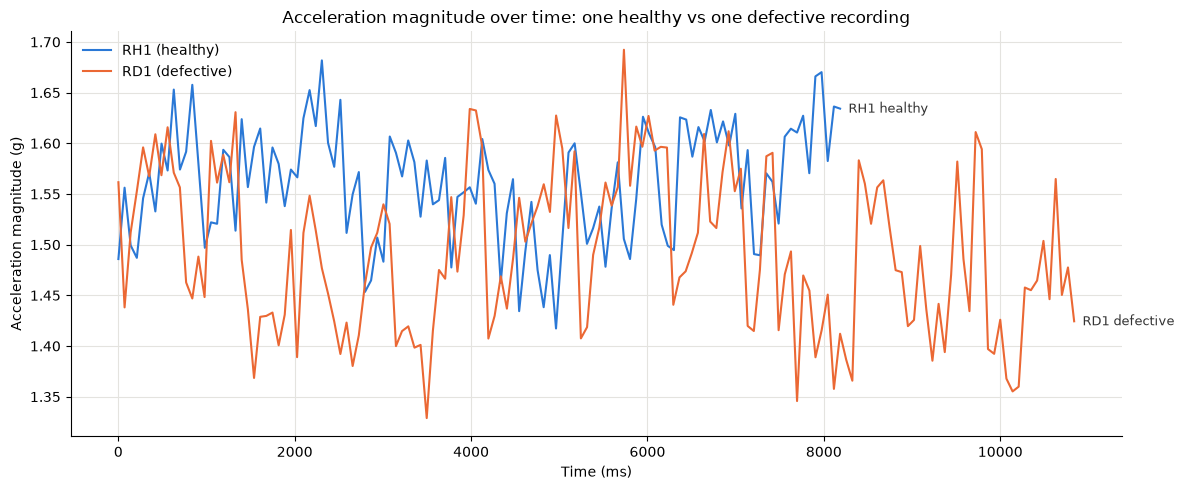

In [16]:
import matplotlib.pyplot as plt

# Pick out the rows for one healthy and one defective recording
rh1 = master[master["recording"] == "RH1"]
rd1 = master[master["recording"] == "RD1"]

HEALTHY_COLOR = "#2a78d6"    # blue
DEFECTIVE_COLOR = "#eb6834"  # orange

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(rh1["Time(ms)"], rh1["Accel_Magnitude(g)"],
        color=HEALTHY_COLOR, linewidth=1.5, label="RH1 (healthy)")
ax.plot(rd1["Time(ms)"], rd1["Accel_Magnitude(g)"],
        color=DEFECTIVE_COLOR, linewidth=1.5, label="RD1 (defective)")

# Label each line at its right-hand end, so you don't have to look at the legend
for df, name in [(rh1, "RH1 healthy"), (rd1, "RD1 defective")]:
    last = df.iloc[-1]
    ax.annotate(name, xy=(last["Time(ms)"], last["Accel_Magnitude(g)"]),
                xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color="#333333")

ax.set_title("Acceleration magnitude over time: one healthy vs one defective recording")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Acceleration magnitude (g)")
ax.legend(frameon=False, loc="upper left")

# Light, unobtrusive background grid; remove the top and right box lines
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()